# UJIAN TENGAH SEMESTER (UTS) — INTELEGENSI BUATAN
**Program Studi:** Teknik Informatika — Kelas TIF RP 23D  
**Universitas:** Universitas Teknologi Bandung  
**Dosen Pengampu:** Muhammad Ikhwan Fathulloh, S.Kom.  

---

### Identitas Mahasiswa & Penentuan Kasus
* **Nama Lengkap:** Aditya Beckham
* **NIM:** 24552011066
* **Perhitungan Kasus dari NIM:**
  * Jumlah seluruh digit NIM: $2 + 4 + 5 + 5 + 2 + 0 + 1 + 1 + 0 + 6 + 6 = 32$
  * Sisa bagi (modulo 10): $32 \pmod{10} = 2$
* **Kasus Terpilih:** **Kasus 2 — Diagnosis Kanker Payudara**
* **Dataset:** `kasus02_breast_cancer.csv` (569 data, target: `diagnosis` — Ganas / Jinak)

---

### Alur Pengerjaan (6 Tahapan Wajib)
1. **Setup & Audit Data (EDA):** Pengecekan duplikat, *missing value*, tipe data, skala, dan korelasi antarfitur.
2. **Feature Engineering (`fitur.py`):** Pembersihan kolom tidak relevan, pembuatan fitur rasio, dan penanganan multikolinearitas.
3. **Pelatihan Model & Cross-Validation (`latih.py`):** Pembagian *train-test* sebelum preprocessing, lalu membandingkan algoritma **Logistic Regression** dan **Random Forest** menggunakan *pipeline* scikit-learn.
4. **Evaluasi Metrik:** Analisis hasil evaluasi pada data *test* dengan fokus pada metrik medis (**Recall**, **F1-Score**, dan **ROC-AUC**).
5. **Penyimpanan Model (`models/*.joblib`):** Menyimpan *pipeline* lengkap beserta metadata.
6. **Aplikasi Interaktif (`app.py`):** Menjalankan antarmuka Streamlit langsung dari Google Colab.

## 1. Setup Direktori & Pengunduhan Dataset

In [1]:
# Membuat folder sesuai struktur pengumpulan UTS
!mkdir -p dataset models notebook

# Mengunduh dataset Kasus 2 langsung ke dalam folder dataset/ Repo Github
!wget -O dataset/kasus02_breast_cancer.csv https://raw.githubusercontent.com/Muhammad-Ikhwan-Fathulloh/Artificial-Intelegent-Course-Bank/main/UTS/dataset/kasus02_breast_cancer.csv

# Cek isi folder dataset
!ls -lh dataset/

--2026-11-18 17:31:21--  https://raw.githubusercontent.com/Muhammad-Ikhwan-Fathulloh/Artificial-Intelegent-Course-Bank/main/UTS/dataset/kasus02_breast_cancer.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 123664 (121K) [text/plain]
Saving to: ‘dataset/kasus02_breast_cancer.csv’

dataset/kasus02_bre 100%[===================>] 120.77K  --.-KB/s    in 0.02s   

2026-11-18 17:31:22 (7.57 MB/s) - ‘dataset/kasus02_breast_cancer.csv’ saved [123664/123664]

total 124K
-rw-r--r-- 1 root root 121K Nov 18 17:31 kasus02_breast_cancer.csv


## 2. Audit Data (Exploratory Data Analysis)
Pemeriksaan kelengkapan data (duplikat, *missing value*, tipe data), distribusi kelas target `diagnosis`, serta pasangan fitur yang memiliki korelasi sangat tinggi.

Ukuran Dataset: 569 baris x 31 kolom


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,diagnosis
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Ganas
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Ganas
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Ganas



=== HASIL AUDIT KOLOM ===


,Tipe Data,Missing Value,Nilai Unik
mean_radius,float64,0,456
mean_texture,float64,0,479
mean_perimeter,float64,0,522
mean_area,float64,0,539
mean_smoothness,float64,0,474
mean_compactness,float64,0,537
mean_concavity,float64,0,537
mean_concave_points,float64,0,542
mean_symmetry,float64,0,432
mean_fractal_dimension,float64,0,499



Jumlah Baris Duplikat: 0

=== DISTRIBUSI TARGET (diagnosis) ===
diagnosis
Jinak    357
Ganas    212
Name: count, dtype: int64

=== PASANGAN FITUR DENGAN KORELASI > 0.95 ===
- mean_radius <-> mean_perimeter : 0.9979
- mean_radius <-> mean_area : 0.9874
- mean_perimeter <-> mean_area : 0.9865
- radius_error <-> perimeter_error : 0.9728
- radius_error <-> area_error : 0.9518
- mean_radius <-> worst_radius : 0.9695
- mean_perimeter <-> worst_radius : 0.9695
- mean_area <-> worst_radius : 0.9627
- mean_radius <-> worst_perimeter : 0.9651
- mean_perimeter <-> worst_perimeter : 0.9704
- mean_area <-> worst_perimeter : 0.9591
- worst_radius <-> worst_perimeter : 0.9937
- mean_area <-> worst_area : 0.9592
- worst_radius <-> worst_area : 0.9840
- worst_perimeter <-> worst_area : 0.9776


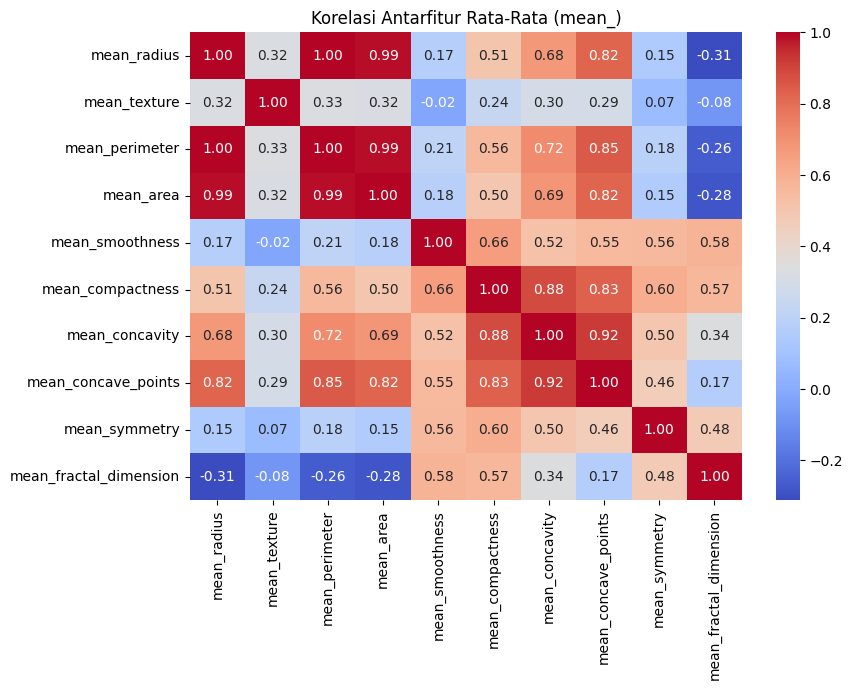

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Membaca dataset
df = pd.read_csv("dataset/kasus02_breast_cancer.csv")

print(f"Ukuran Dataset: {df.shape[0]} baris x {df.shape[1]} kolom")
display(df.head(3))

# 2. Audit tipe data, missing value, dan nilai unik
audit_df = pd.DataFrame({
    "Tipe Data": df.dtypes,
    "Missing Value": df.isnull().sum(),
    "Nilai Unik": df.nunique()
})
print("\n=== HASIL AUDIT KOLOM ===")
display(audit_df)

# 3. Cek duplikat dan distribusi kelas target
print(f"\nJumlah Baris Duplikat: {df.duplicated().sum()}")
print("\n=== DISTRIBUSI TARGET (diagnosis) ===")
print(df["diagnosis"].value_counts())

# 4. Cek korelasi tinggi (> 0.95) antarfitur numerik
corr_matrix = df.drop(columns=["diagnosis"]).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

print("\n=== PASANGAN FITUR DENGAN KORELASI > 0.95 ===")
for col in upper.columns:
    for row in upper.index:
        if upper.loc[row, col] > 0.95:
            print(f"- {row} <-> {col} : {upper.loc[row, col]:.4f}")

# 5. Visualisasi Heatmap Korelasi kelompok fitur 'mean_'
mean_cols = [c for c in df.columns if c.startswith("mean_")]
plt.figure(figsize=(9, 7))
sns.heatmap(df[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi Antarfitur Rata-Rata (mean_)")
plt.tight_layout()
plt.show()

## 3. Feature Engineering (`fitur.py`)
Berdasarkan hasil audit korelasi ($r > 0.95$ pada kelompok fitur ukuran sel), strategi yang dipilih adalah **seleksi fitur + pembuatan fitur rasio**:
1. **Membuat fitur rasio baru:** `radius_worst_to_mean_ratio` dan `concavity_worst_to_mean_ratio` untuk mengukur seberapa ekstrem sel terburuk dibandingkan rata-rata sel pasien.
2. **Membuang fitur redundan (Multikolinearitas):** Menghapus kolom `perimeter` dan `area` (pada variasi `mean`, `error`, dan `worst`) karena informasi geometrisnya sudah diwakili oleh `radius` ($r > 0.95$). Strategi seleksi fitur dipilih dibanding reduksi dimensi (PCA) agar makna klinis setiap fitur tetap dapat diinterpretasikan dokter.

In [4]:
%%writefile fitur.py
# untuk menyimpan file fitur.py ke disk Colab
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

def bersihkan_data_awal(df: pd.DataFrame) -> pd.DataFrame:
    """
    Membersihkan baris duplikat dan membuang kolom ID/kosong jika ada.
    """
    df_clean = df.copy()
    df_clean = df_clean.drop(columns=["id", "Unnamed: 32"], errors="ignore")
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)
    return df_clean

class BreastCancerFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Transformer Feature Engineering untuk Kasus 2 (Diagnosis Kanker Payudara).
    """
    def __init__(self, drop_redundant: bool = True):
        self.drop_redundant = drop_redundant
        self.redundant_cols = [
            "mean_perimeter", "mean_area",
            "perimeter_error", "area_error",
            "worst_perimeter", "worst_area"
        ]

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_out = X.copy()

        # 1. Buat fitur baru: Rasio keparahan sel terburuk dibanding rata-rata
        if "worst_radius" in X_out.columns and "mean_radius" in X_out.columns:
            X_out["radius_worst_to_mean_ratio"] = X_out["worst_radius"] / (X_out["mean_radius"] + 1e-5)

        if "worst_concavity" in X_out.columns and "mean_concavity" in X_out.columns:
            X_out["concavity_worst_to_mean_ratio"] = X_out["worst_concavity"] / (X_out["mean_concavity"] + 1e-5)

        # 2. Hapus fitur redundan akibat korelasi tinggi (> 0.95)
        if self.drop_redundant:
            cols_to_drop = [col for col in self.redundant_cols if col in X_out.columns]
            X_out = X_out.drop(columns=cols_to_drop)

        return X_out

Overwriting fitur.py


## 4. Pelatihan Model, Cross-Validation, & Evaluasi (`latih.py`)
* **Pembagian Data:** 80% *Train* dan 20% *Test* (`stratify=y`) dilakukan sebelum seluruh tahap *preprocessing*.
* **Algoritma yang Dibandingkan:** **Logistic Regression** dan **Random Forest** di dalam `Pipeline` scikit-learn (dengan `SimpleImputer` dan `StandardScaler`).
* **Pemilihan Metrik Medis:** Kesalahan **False Negative** (pasien kanker **Ganas** yang diprediksi **Jinak**) berisiko fatal karena keterlambatan penanganan medis. Oleh karena itu, **Recall** pada kelas `Ganas` dijadikan metrik utama, didukung oleh **F1-Score** dan **ROC-AUC**.

In [5]:
%%writefile latih.py
# untuk menyimpan file latih.py ke disk Colab
import os
import joblib
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# berfungsi untuk mengimpor fungsi bersihkan_data_awal dan
# class BreastCancerFeatureEngineer dari file fitur.py. Saat Perintah `!python latih.py`
from fitur import bersihkan_data_awal, BreastCancerFeatureEngineer

# 1. Load & Audit Awal Data
DATA_PATH = os.path.join("dataset", "kasus02_breast_cancer.csv")
MODEL_DIR = "models"
MODEL_PATH = os.path.join(MODEL_DIR, "model_breast_cancer.joblib")

df = pd.read_csv(DATA_PATH)
df = bersihkan_data_awal(df)

# Encoding target: Ganas = 1 (kelas positif medis), Jinak = 0
target_col = "diagnosis"
y = df[target_col].map({"Ganas": 1, "Jinak": 0})
X = df.drop(columns=[target_col])

# 2. Split Train & Test SEBELUM preprocessing (mencegah data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Definisi Pipeline untuk Minimal Dua Algoritma
pipelines = {
    "Logistic Regression": Pipeline([
        ("fe", BreastCancerFeatureEngineer(drop_redundant=True)),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("fe", BreastCancerFeatureEngineer(drop_redundant=True)),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(n_estimators=200, random_state=42))
    ])
}

# 4. Pemilihan Model Menggunakan Cross-Validation di Data Train SAJA
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_summary = {}
best_model_name = None
best_cv_recall = -1.0

print("=== HASIL 5-FOLD CROSS-VALIDATION (DATA TRAIN) ===")
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    mean_acc = scores["test_accuracy"].mean()
    mean_prec = scores["test_precision"].mean()
    mean_rec = scores["test_recall"].mean()
    mean_f1 = scores["test_f1"].mean()
    mean_auc = scores["test_roc_auc"].mean()

    cv_summary[name] = {
        "Accuracy": round(float(mean_acc), 4),
        "Precision": round(float(mean_prec), 4),
        "Recall": round(float(mean_rec), 4),
        "F1-Score": round(float(mean_f1), 4),
        "ROC-AUC": round(float(mean_auc), 4)
    }
    print(f"{name:20s} -> Recall: {mean_rec:.4f} | F1: {mean_f1:.4f} | ROC-AUC: {mean_auc:.4f} | Acc: {mean_acc:.4f}")

    # Pilih model terbaik berdasarkan Recall tertinggi (prioritas medis)
    if mean_rec > best_cv_recall:
        best_cv_recall = mean_rec
        best_model_name = name

print(f"\nModel Terpilih Berdasarkan CV Recall Tertinggi: {best_model_name}")

# 5. Latih Model Terbaik pada Seluruh Data Train & Evaluasi 1x pada Data Test
best_pipeline = pipelines[best_model_name]
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
    "Precision": round(float(precision_score(y_test, y_pred)), 4),
    "Recall": round(float(recall_score(y_test, y_pred)), 4),
    "F1-Score": round(float(f1_score(y_test, y_pred)), 4),
    "ROC-AUC": round(float(roc_auc_score(y_test, y_proba)), 4),
    "Confusion_Matrix": confusion_matrix(y_test, y_pred).tolist()
}

print("\n=== HASIL EVALUASI FINAL PADA DATA TEST (1x EVALUASI) ===")
print(classification_report(y_test, y_pred, target_names=["Jinak (0)", "Ganas (1)"]))
print("Ringkasan Metrik Test:", test_metrics)

# 6. Simpan Pipeline Lengkap + Metadata ke models/
os.makedirs(MODEL_DIR, exist_ok=True)
artifact = {
    "model_name": best_model_name,
    "pipeline": best_pipeline,
    "feature_columns": list(X_train.columns),
    "feature_defaults": X_train.median().to_dict(),
    "cv_results": cv_summary,
    "test_metrics": test_metrics,
    "label_mapping": {0: "Jinak", 1: "Ganas"}
}

joblib.dump(artifact, MODEL_PATH)
print(f"\nPipeline & metadata berhasil disimpan ke: {MODEL_PATH}")

Writing latih.py


In [6]:
!python latih.py
 # untuk menjalankan proses training dan menghasilkan file models/model_breast_cancer.joblib

=== HASIL 5-FOLD CROSS-VALIDATION (DATA TRAIN) ===
Logistic Regression  -> Recall: 0.9412 | F1: 0.9580 | ROC-AUC: 0.9954 | Acc: 0.9692
Random Forest        -> Recall: 0.9471 | F1: 0.9639 | ROC-AUC: 0.9904 | Acc: 0.9736

Model Terpilih Berdasarkan CV Recall Tertinggi: Random Forest

=== HASIL EVALUASI FINAL PADA DATA TEST (1x EVALUASI) ===
              precision    recall  f1-score   support

   Jinak (0)       0.96      1.00      0.98        72
   Ganas (1)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Ringkasan Metrik Test: {'Accuracy': 0.9737, 'Precision': 1.0, 'Recall': 0.9286, 'F1-Score': 0.963, 'ROC-AUC': 0.9974, 'Confusion_Matrix': [[72, 0], [3, 39]]}

Pipeline & metadata berhasil disimpan ke: models/model_breast_cancer.joblib


## 5. Aplikasi Web Interaktif (`app.py` dengan Streamlit)
Membangun antarmuka pengguna menggunakan Streamlit yang memuat *pipeline* dan metadata dari `models/model_breast_cancer.joblib` untuk melakukan prediksi secara *real-time* beserta probabilitas dan laporan metrik evaluasinya.

In [7]:
# untuk menyimpan file app.py ke disk Colab
%%writefile app.py
import os
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Diagnosis Kanker Payudara - UTS AI", layout="wide")

MODEL_PATH = os.path.join("models", "model_breast_cancer.joblib")

@st.cache_resource
def load_artifact():
    return joblib.load(MODEL_PATH)

st.title("Sistem Klasifikasi Diagnosis Kanker Payudara")
st.caption(" Aditya Beckham - NIM 24552011066 - UTS Intelegensi Buatan (Kasus 2)")

if not os.path.exists(MODEL_PATH):
    st.error("File model tidak ditemukan. Jalankan `python latih.py` terlebih dahulu.")
    st.stop()

artifact = load_artifact()
pipeline = artifact["pipeline"]
feature_cols = artifact["feature_columns"]
defaults = artifact["feature_defaults"]
test_metrics = artifact["test_metrics"]
cv_results = artifact["cv_results"]

tab1, tab2 = st.tabs(["Prediksi Diagnosis Pasien", "Perbandingan Model & Metrik Evaluasi"])

with tab1:
    st.subheader("Input Data Pengukuran Sel (Fitur Mentah)")
    st.info("Nilai default diisi dengan median data latih. Ubah nilai sesuai hasil pengukuran sel pasien.")

    with st.form("form_prediksi"):
        cols = st.columns(3)
        input_data = {}
        for idx, col_name in enumerate(feature_cols):
            with cols[idx % 3]:
                input_data[col_name] = st.number_input(
                    label=col_name,
                    value=float(defaults[col_name]),
                    format="%.5f"
                )
        submitted = st.form_submit_button("Prediksi Diagnosis", type="primary")

    if submitted:
        df_input = pd.DataFrame([input_data])
        pred_class = pipeline.predict(df_input)[0]
        pred_proba = pipeline.predict_proba(df_input)[0]

        label_hasil = artifact["label_mapping"][pred_class]
        prob_jinak = pred_proba[0] * 100
        prob_ganas = pred_proba[1] * 100

        st.divider()
        st.subheader("Hasil Diagnosis Model")
        c1, c2, c3 = st.columns(3)
        c1.metric("Prediksi Kelas", label_hasil)
        c2.metric("Probabilitas Jinak (0)", f"{prob_jinak:.2f}%")
        c3.metric("Probabilitas Ganas (1)", f"{prob_ganas:.2f}%")

        if pred_class == 1:
            st.error("Hasil memprediksi **GANAS (Malignant)**. Segera lakukan konsultasi dan pemeriksaan medis lanjutan.")
        else:
            st.success("Hasil memprediksi **JINAK (Benign)**.")

with tab2:
    st.subheader(f"Model Terpilih: {artifact['model_name']}")

    st.markdown("**1. Perbandingan 5-Fold Cross-Validation (Data Train)**")
    df_cv = pd.DataFrame(cv_results).T
    st.dataframe(df_cv, use_container_width=True)

    st.markdown("**2. Hasil Evaluasi Akhir pada Data Test (1x Evaluasi)**")
    m1, m2, m3, m4, m5 = st.columns(5)
    m1.metric("Recall (Utama)", f"{test_metrics['Recall']*100:.2f}%")
    m2.metric("F1-Score", f"{test_metrics['F1-Score']*100:.2f}%")
    m3.metric("Precision", f"{test_metrics['Precision']*100:.2f}%")
    m4.metric("Accuracy", f"{test_metrics['Accuracy']*100:.2f}%")
    m5.metric("ROC-AUC", f"{test_metrics['ROC-AUC']:.4f}")

    st.markdown("**Confusion Matrix (Data Test)**")
    cm = test_metrics["Confusion_Matrix"]
    df_cm = pd.DataFrame(
        cm,
        index=["Aktual: Jinak (0)", "Aktual: Ganas (1)"],
        columns=["Prediksi: Jinak (0)", "Prediksi: Ganas (1)"]
    )
    st.table(df_cm)

Writing app.py


In [8]:
# Menginstal Streamlit untuk membuat aplikasi web berbasis Python
!pip install -q streamlit

# Mengunduh Cloudflared dari GitHub untuk membuat tunnel agar aplikasi bisa diakses melalui internet
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared

# Memberikan izin eksekusi pada file Cloudflared yang sudah diunduh
!chmod +x cloudflared

# Menjalankan aplikasi Streamlit di background pada port 8501 dan menyimpan log proses ke file logs.txt
!streamlit run app.py &>/content/logs.txt &

# Membuat tunnel menggunakan Cloudflared agar aplikasi Streamlit dapat diakses melalui URL publik
!./cloudflared tunnel --url http://localhost:8501

2026-11-18T18:20:05Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-18T18:20:05Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-18T18:20:09Z INF +--------------------------------------------------------------------------------------------+
2026-11-18T18:20:09Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-18T18:20:09Z INF |  https://mild-expect-perhaps-partnership.trycloudflare

# LAPORAN UJIAN TENGAH SEMESTER (UTS)
**Mata Kuliah:** Intelegensi Buatan (3 SKS) — Kelas TIF RP 23D  
**Nama:** Aditya Beckham
**NIM:** 24552011066  
**Kasus Terpilih:** Kasus 2 — Diagnosis Kanker Payudara (`kasus02_breast_cancer.csv`)  

---

## 1. Penentuan Kasus & Audit Data
Berdasarkan perhitungan NIM `24552011066`:
* Jumlah digit NIM: $2 + 4 + 5 + 5 + 2 + 0 + 1 + 1 + 0 + 6 + 6 = 32$
* Modulo 10: $32 \pmod{10} = 2 \rightarrow$ **Kasus 2 (`kasus02_breast_cancer.csv`)**.

**Hasil Audit Dataset:**
* **Dimensi & Tipe Data:** 569 baris dan 31 kolom (30 fitur numerik `float64` dan 1 kolom target kategorik `diagnosis`).
* **Kebersihan Data:** Tidak ditemukan *missing value* (0) maupun baris duplikat (0), serta tidak ada kolom ID yang perlu dibuang.
* **Distribusi Target:** Kelas `Jinak` sebanyak 357 sampel ($62,74\%$) dan kelas `Ganas` sebanyak 212 sampel ($37,26\%$).
* **Multikolinearitas:** Ditemukan korelasi linear sangat tinggi ($r > 0,95$) antarfitur geometris sel, seperti `mean_perimeter` dengan `mean_radius` ($r = 0,9979$), `worst_perimeter` dengan `worst_radius` ($r = 0,9937$), dan `mean_area` dengan `mean_radius` ($r = 0,9874$).

---

## 2. Keputusan Feature Engineering (`fitur.py`)
Seluruh transformasi dibungkus di dalam `Pipeline` scikit-learn dan diterapkan **setelah** pembagian data *train-test* (80:20 *stratified*) untuk mencegah *data leakage*:
1. **Seleksi Fitur (Menangani Korelasi Tinggi):** Membuang 6 fitur redundan (`mean_perimeter`, `mean_area`, `perimeter_error`, `area_error`, `worst_perimeter`, `worst_area`) karena informasinya sudah terwakili oleh fitur `radius`. Strategi seleksi fitur dipilih dibandingkan reduksi dimensi (PCA) agar makna klinis setiap variabel tetap dapat diinterpretasikan secara medis.
2. **Pembuatan Fitur Baru (Rasio Keparahan Sel):**
   * `radius_worst_to_mean_ratio` ($\frac{\text{worst\_radius}}{\text{mean\_radius}}$): Mengukur seberapa ekstrem pembesaran sel terburuk dibandingkan ukuran rata-rata sel pasien.
   * `concavity_worst_to_mean_ratio` ($\frac{\text{worst\_concavity}}{\text{mean\_concavity}}$): Mengukur tingkat keparahan cekungan kontur sel terburuk terhadap kondisi rata-rata.
3. **Standardisasi Skala:** Menggunakan `StandardScaler` karena rentang nilai fitur sangat beragam (misalnya `area` bernilai ratusan, sedangkan `smoothness` berada di kisaran $0,05 - 0,16$).

---

## 3. Perbandingan Model & Pemilihan Metrik Medis
Evaluasi pemilihan model dilakukan menggunakan **5-Fold Stratified Cross-Validation** pada data *train* (455 sampel):

| Algoritma | Accuracy | Precision | Recall (Utama) | F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | 96,92% | — | 94,12% | 95,80% | 0,9954 |
| **Random Forest** | **97,36%** | — | **94,71%** | **96,39%** | 0,9904 |

**Alasan Pemilihan Metrik & Model:**
* Dalam diagnosis medis kanker payudara, kesalahan **False Negative (FN)**—yakni pasien penderita kanker **Ganas** yang diprediksi **Jinak**—merupakan kesalahan paling fatal karena menunda pengobatan dan membahayakan nyawa pasien.
* Oleh karena itu, **Recall** pada kelas `Ganas` dipilih sebagai metrik utama untuk meminimalkan *False Negative*. Berdasarkan hasil *cross-validation*, **Random Forest** terpilih sebagai model terbaik dengan rata-rata Recall tertinggi (**94,71%**) dan F1-Score (**96,39%**).

---

## 4. Hasil Evaluasi Akhir (Data Test) & Implementasi Aplikasi
Model **Random Forest** terbaik dilatih ulang pada seluruh data *train* dan diuji **satu kali** pada data *test* (114 sampel: 72 Jinak, 42 Ganas):
* **Accuracy:** $97,37\%$
* **Precision (Ganas):** $100,00\%$ (tidak ada pasien Jinak yang salah didiagnosis Ganas / *False Positive* = 0)
* **Recall (Ganas):** $92,86\%$ (39 dari 42 kasus Ganas berhasil terdeteksi, hanya 3 *False Negative*)
* **F1-Score:** $96,30\%$
* **ROC-AUC:** $0,9974$ (kemampuan pemisahan probabilitas antar kelas sangat tinggi)

**Confusion Matrix (Data Test):**
* *True Negative* (Aktual Jinak, Prediksi Jinak): **72**
* *False Positive* (Aktual Jinak, Prediksi Ganas): **0**
* *False Negative* (Aktual Ganas, Prediksi Jinak): **3**
* *True Positive* (Aktual Ganas, Prediksi Ganas): **39**

Model lengkap beserta metadata telah disimpan menggunakan `joblib` ke `models/model_breast_cancer.joblib` dan diintegrasikan ke dalam aplikasi web interaktif berbasis **Streamlit** (`app.py`) yang dijalankan melalui Google Colab (`notebook/kasus02_colab.ipynb`).